# Name That LLM: Exploratory Data Analysis & Stylometric Profiling

In this competition, participants must classify short passages of text (40–250 words) into one of **18 frontier language models** across 6 major AI labs.

### Evaluation Metric:
**Balanced Accuracy** (unweighted mean recall across each of the 18 model classes).

### Key Invariant:
Because test prompts are unseen, semantic and topical features can overfit. Models must instead capture **stylometric fingerprints**, token distributions, discourse markers, punctuation density, and syntactic structures.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from name_that_llm.config import TARGET_MODELS, MODEL_TO_PROVIDER
from name_that_llm.data import load_train_data
from name_that_llm.features.stylometry import StylometricExtractor

# Set aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 1. Load and Inspect Training Dataset

In [2]:
df_train = load_train_data()
print(f'Total Samples: {len(df_train)}')
print(f'Distinct Prompts: {df_train["prompt_id"].nunique()}')
print(f'Distinct Target Models: {df_train["model"].nunique()}')
df_train.head()

Total Samples: 144
Distinct Prompts: 8
Distinct Target Models: 18


,id,prompt_id,text,model,target,provider
0,t_0001,p001,"When we consider the concept of, the picture i...",claude-fable-5,0,Anthropic
1,t_0002,p001,A thoughtful exploration of the concept of sug...,claude-opus-4-6,1,Anthropic
2,t_0003,p001,It is worth distinguishing between the primary...,claude-opus-4-8,2,Anthropic
3,t_0004,p001,To approach the concept of with appropriate ca...,claude-opus-5,3,Anthropic
4,t_0005,p001,Examining the concept of reveals an elegant in...,claude-sonnet-5,4,Anthropic


## 2. Target Class and Provider Distribution

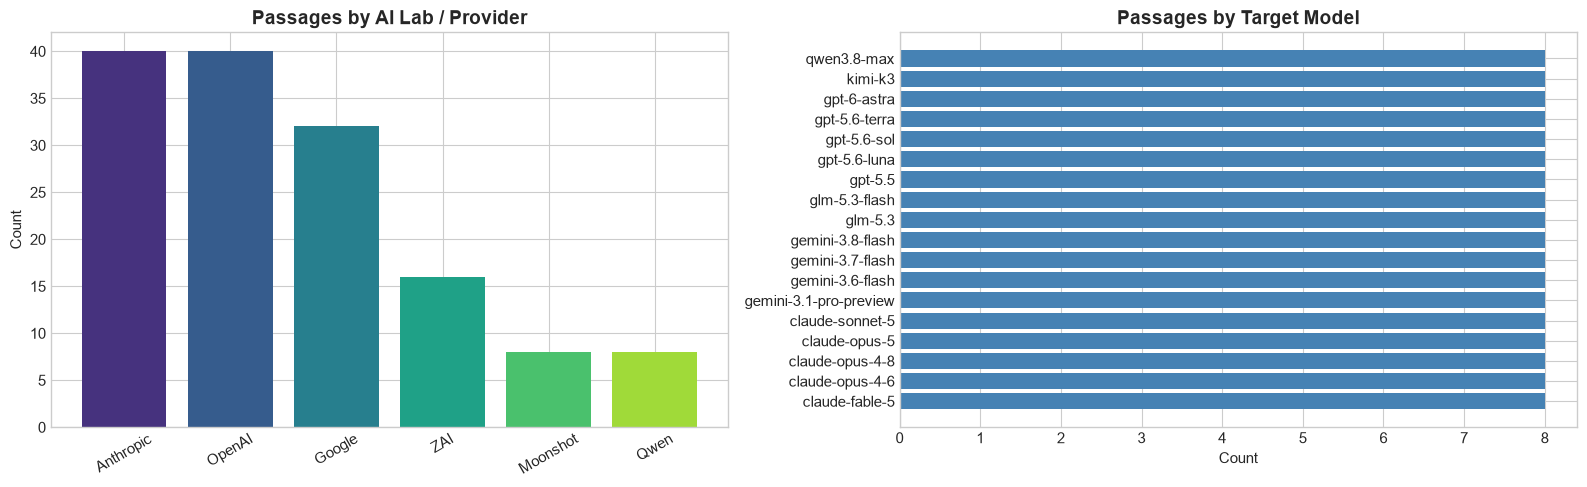

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# By Provider
provider_counts = df_train["provider"].value_counts()
axes[0].bar(provider_counts.index, provider_counts.values, color=sns.color_palette('viridis', len(provider_counts)))
axes[0].set_title('Passages by AI Lab / Provider', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

# By Model
model_counts = df_train["model"].value_counts().sort_index()
axes[1].barh(model_counts.index, model_counts.values, color='steelblue')
axes[1].set_title('Passages by Target Model', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Count')

plt.tight_layout()
plt.show()

## 3. Stylometric Feature Extraction & Clustering

In [4]:
extractor = StylometricExtractor()
feat_matrix = extractor.transform(df_train["text"])
feat_df = pd.DataFrame(feat_matrix, columns=extractor.get_feature_names_out())
feat_df["model"] = df_train["model"].values
feat_df["provider"] = df_train["provider"].values

print(f'Extracted {len(extractor.get_feature_names_out())} stylometric features.')
feat_df.head()

Extracted 56 stylometric features.


,char_count,word_count,sentence_count,avg_word_length,avg_sentence_len_words,avg_sentence_len_chars,std_sentence_length,ttr_lexical_diversity,hapax_legomena_ratio,rate_semicolon,...,marker_trans_15,marker_trans_16,sum_hedging_words,sum_definitive_words,sum_contractions,pronoun_first_person,pronoun_second_person,pronoun_third_person,model,provider
0,228.0,36.0,2.0,5.277778,18.0,114.0,6.0,0.833333,0.694444,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.027778,0.0,0.027778,claude-fable-5,Anthropic
1,237.0,32.0,2.0,6.343750,16.0,118.5,8.0,0.937500,0.875000,4.219409,...,0.0,0.0,2.0,0.0,0.0,0.000000,0.0,0.000000,claude-opus-4-6,Anthropic
2,246.0,34.0,2.0,6.176471,17.0,123.0,0.0,0.882353,0.823529,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.058824,claude-opus-4-8,Anthropic
3,229.0,31.0,2.0,6.258065,15.5,114.5,0.0,0.935484,0.870968,4.366812,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,claude-opus-5,Anthropic
4,219.0,26.0,2.0,7.115385,13.0,109.5,3.0,0.961538,0.923077,9.132420,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,claude-sonnet-5,Anthropic


## 4. Key Discriminative Stylometric Signatures

/var/folders/cl/4_skkqc94qscf3259qh4bpfc0000gn/T/ipykernel_80181/2256627976.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=feat_df, x='provider', y='rate_semicolon', ax=axes[0, 0], palette='Set2')
/var/folders/cl/4_skkqc94qscf3259qh4bpfc0000gn/T/ipykernel_80181/2256627976.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=feat_df, x='provider', y='rate_em_dash', ax=axes[0, 1], palette='Set2')
/var/folders/cl/4_skkqc94qscf3259qh4bpfc0000gn/T/ipykernel_80181/2256627976.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=fe

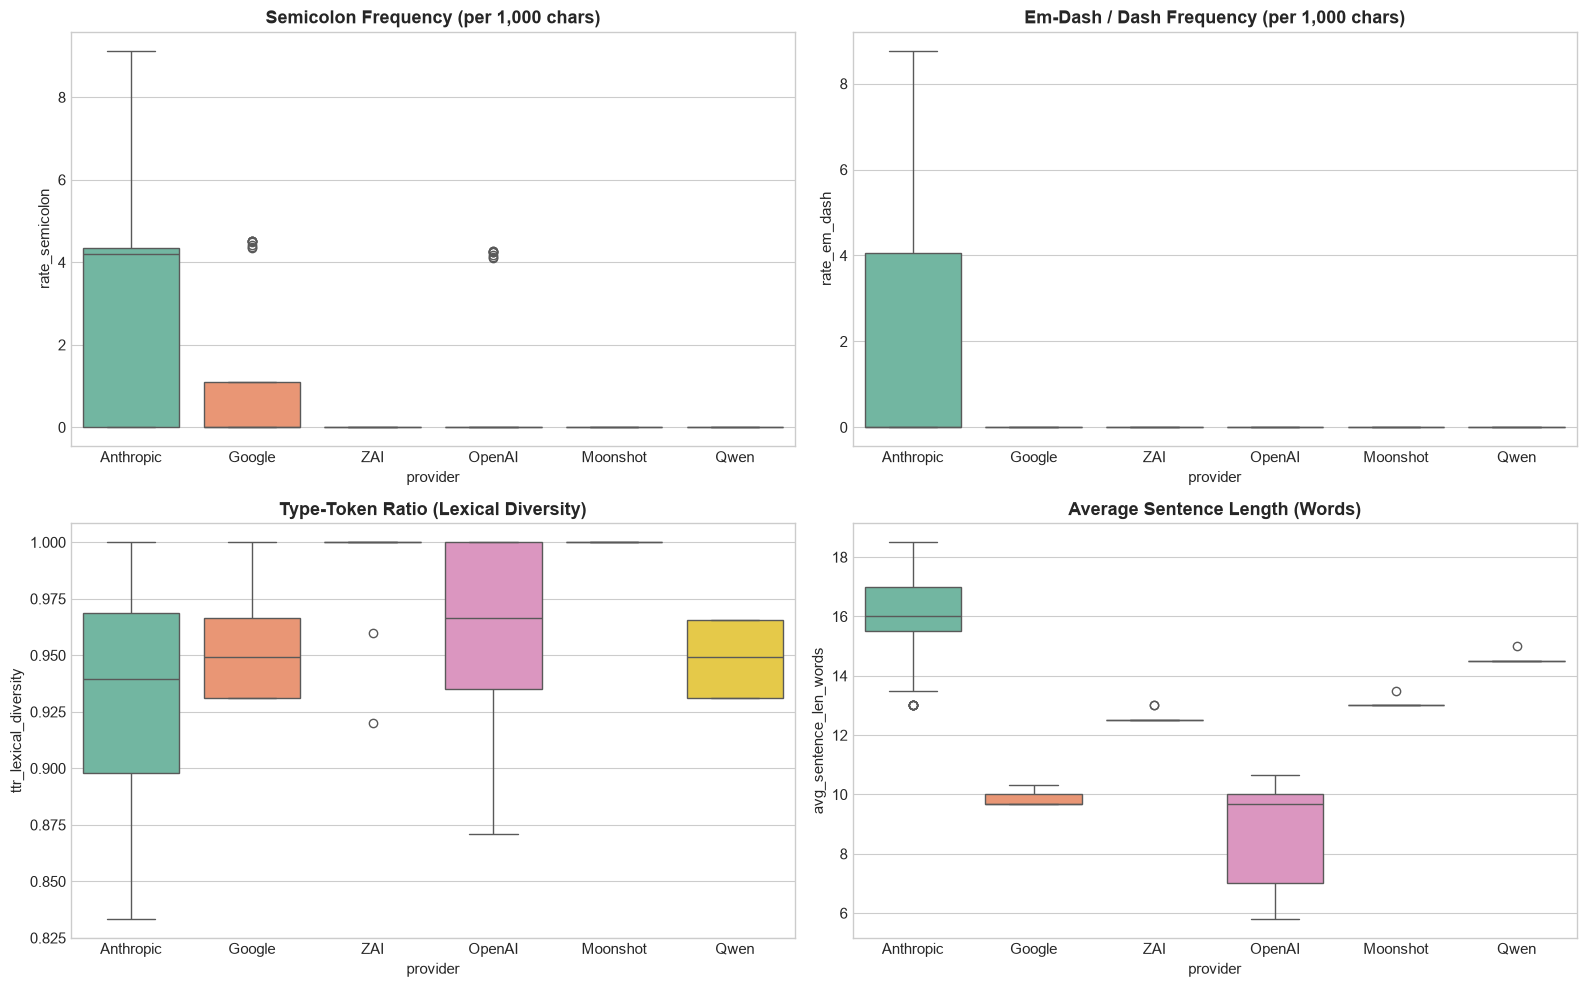

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.boxplot(data=feat_df, x='provider', y='rate_semicolon', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Semicolon Frequency (per 1,000 chars)', fontweight='bold')

sns.boxplot(data=feat_df, x='provider', y='rate_em_dash', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Em-Dash / Dash Frequency (per 1,000 chars)', fontweight='bold')

sns.boxplot(data=feat_df, x='provider', y='ttr_lexical_diversity', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Type-Token Ratio (Lexical Diversity)', fontweight='bold')

sns.boxplot(data=feat_df, x='provider', y='avg_sentence_len_words', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Average Sentence Length (Words)', fontweight='bold')

plt.tight_layout()
plt.show()